In [1]:
import sys
import importlib.util

print("Python:", sys.executable)
import geopandas as gpd
print("geopandas from:", gpd.__file__)

for name in ["statsmodels", "scipy", "sklearn", "pyspark", "pymongo"]:
    print(name, "found" if importlib.util.find_spec(name) else "MISSING")

Python: /home/yamama/spark-env/bin/python
geopandas from: /home/yamama/spark-env/lib/python3.11/site-packages/geopandas/__init__.py
statsmodels found
scipy found
sklearn found
pyspark found
pymongo found


In [2]:
import geopandas as gpd
import statsmodels
import scipy
import sklearn

print("geopandas", gpd.__version__)
print("statsmodels", statsmodels.__version__)
print("scipy", scipy.__version__)
print("scikit-learn", sklearn.__version__)

geopandas 1.2.0
statsmodels 0.15.0
scipy 1.17.1
scikit-learn 1.9.1


In [ ]:
from pathlib import Path
import geopandas as gpd

# Find all shapefiles unpacked from the NVE download
shp_files = list(Path("../data").rglob("*.shp"))
for f in shp_files:
       print(f)

../data/NVEKartdata/NVEData/Nedborfelt/Nedborfelt_Vassdragsomr.shp


In [7]:
from pathlib import Path
import geopandas as gpd

# Read every shapefile unpacked from the NVE download and print a short summary
shp_files = sorted(Path("../data").rglob("*.shp"))
for f in shp_files:
    gdf = gpd.read_file(f)
    print(f.name, "| rows:", len(gdf), "| EPSG:", gdf.crs.to_epsg() if gdf.crs else None)
    print("   columns:", gdf.columns.tolist())

Nedborfelt_Vassdragsomr.shp | rows: 306 | EPSG: 25833
   columns: ['objType', 'vassOmrNr', 'vassOmr', 'arealLand', 'areal_km2', 'uttakDato', 'ekspType', 'geometry']


In [8]:
from pathlib import Path
import geopandas as gpd

# Read every shapefile unpacked from the NVE download and print a short summary
shp_files = sorted(Path("../data").rglob("*.shp"))
for f in shp_files:
    gdf = gpd.read_file(f)
    print(f.name, "| rows:", len(gdf), "| EPSG:", gdf.crs.to_epsg() if gdf.crs else None)
    print("   columns:", gdf.columns.tolist())

Nedborfelt_Vassdragsomr.shp | rows: 306 | EPSG: 25833
   columns: ['objType', 'vassOmrNr', 'vassOmr', 'arealLand', 'areal_km2', 'uttakDato', 'ekspType', 'geometry']


In [9]:
from pathlib import Path
import geopandas as gpd

# Look at the region names in the watercourse/precipitation layer we already have
gdf = gpd.read_file(next(Path("../data").rglob("*.shp")))
print("Unique vassOmr values:", gdf["vassOmr"].nunique())
print(sorted(gdf["vassOmr"].dropna().unique())[:60])
print(gdf.groupby("vassOmrNr").size().head(20))

Unique vassOmr values: 306
['ALBERT I LAND', 'ANDREE LAND ØST', 'Adamselvvassdraget/indre Laksefjorden øst', 'Alsten og Tjøtta', 'Altavassdraget/Altafjorden', 'Andørja', 'Andøya', 'Arendalsvassdraget/kyst Moland-Homborsund', 'Arnøya og Laukøya', 'Askøya og Holsnøya', 'Audna/kyst Mandal by-Lindesnes', 'Aukra, Misund og Sandøy kommuner', 'Aulivassdraget/kyst Tønsberg-Sandefjord', 'Aurlandsvassdraget/Aurlandsfjorden', 'Averøy, Frei og Kristiansund kommuner', 'BARENTSØYA', 'BILLEFJORDEN', 'BJØRNØYA', 'BRAGANZAVÅGEN/KJELSTRÖMELVA', 'Beiarelva, Morsdalsfjorden og Nordfjorden', 'Bergebyelva og Vesterelva/indre Varangerfjord', 'Bergen og omegn', 'Bergsdalsvassdraget/kyst Salhus-Dale', 'Bindalsfjorden nord', 'Bjerkreimvassdraget/kyst Sokndal-Ogna', 'Blåelva/kyst Etnefjorden-Sunde', 'Breimsvassdraget/Nordfjord sør: Hyenfjorden-Innvik', 'Bremangerlandet', 'Bømlo', 'Børselvvassdraget/indre Porsangen øst', 'DICKSONFJORDEN/DICSONELVA', 'Dalelven', 'Drammensvassdraget/Drammensfjorden vest', 'Driva/tT

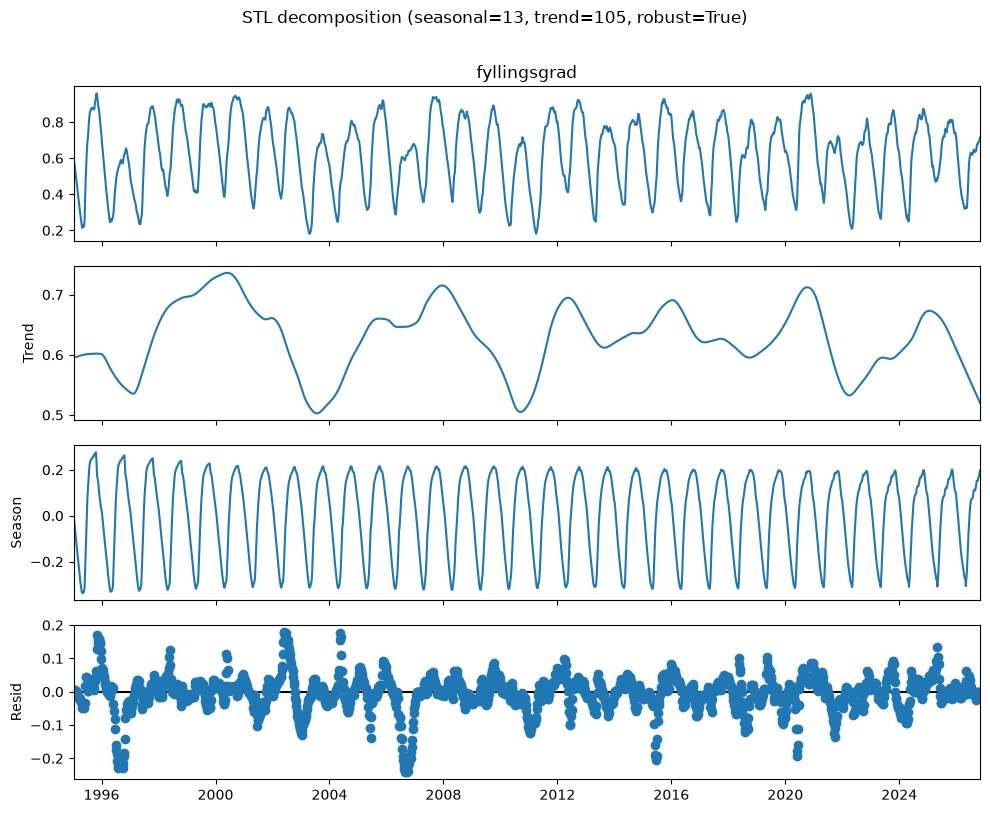

In [10]:
# --- STL decomposition of the reservoir filling degree --------------------
import requests
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"


def load_fill_series(omr_type="NO", omr_nr=0):
    """Weekly filling degree for one area, downloaded from the NVE API."""
    resp = requests.get(f"{BASE}/HentOffentligData", timeout=30)
    resp.raise_for_status()
    df = pd.DataFrame(resp.json())
    df["dato_Id"] = pd.to_datetime(df["dato_Id"])
    df = df[(df["omrType"] == omr_type) & (df["omrnr"] == omr_nr)]
    series = df.sort_values("dato_Id").set_index("dato_Id")["fyllingsgrad"]
    # STL needs a regular weekly index (weeks start on Sunday in this data)
    return series.asfreq("W-SUN").interpolate()


def stl_decomposition(series, period=52, seasonal=13, trend=105, robust=True):
    """Seasonal-trend decomposition using LOESS.

    seasonal: seasonal smoother length (odd number >= 3)
    trend: trend smoother length (odd number, larger than the period)
    robust: reduce the influence of outliers if True
    Returns the figure and the STL result.
    """
    result = STL(series, period=period, seasonal=seasonal,
                 trend=trend, robust=robust).fit()
    fig = result.plot()
    fig.set_size_inches(10, 8)
    fig.suptitle(f"STL decomposition (seasonal={seasonal}, trend={trend}, robust={robust})",
                 y=1.01)
    plt.tight_layout()
    return fig, result


# Test the function on the national level
fill = load_fill_series("NO", 0)
fig, stl_result = stl_decomposition(fill)
plt.show()

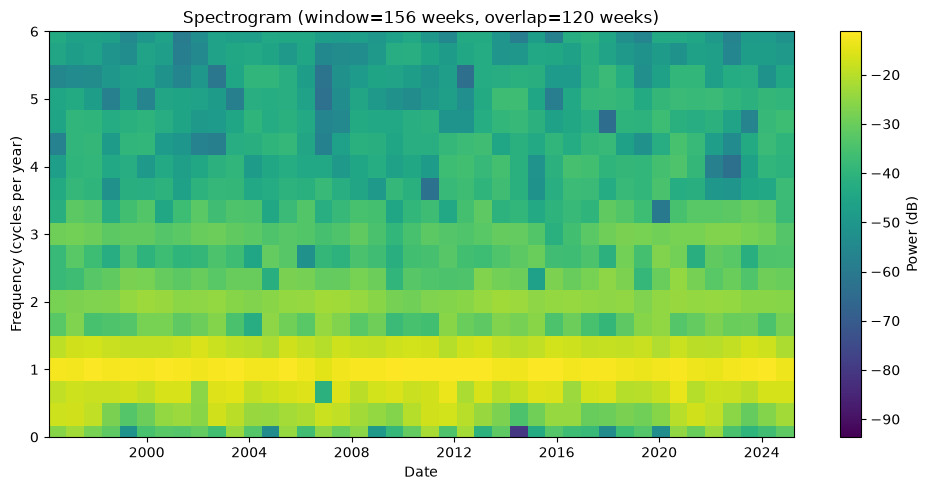

In [11]:
# --- Spectrogram of the filling degree ------------------------------------
import numpy as np
from scipy.signal import spectrogram


def make_spectrogram(series, window_length=156, overlap=120, max_freq=6):
    """Spectrogram of a weekly series.

    window_length: samples (weeks) per window; 156 weeks = 3 years
    overlap: samples shared by neighbouring windows (must be < window_length)
    max_freq: highest frequency to show, in cycles per year
    Returns the figure.
    """
    if overlap >= window_length:
        raise ValueError("overlap must be smaller than window_length")

    # Weekly data means 52 samples per year, so frequencies come out in cycles/year
    values = series.to_numpy() - series.mean()
    freqs, times, power = spectrogram(values, fs=52, window="hann",
                                      nperseg=window_length, noverlap=overlap)

    # Convert the time axis (years from start) to dates
    dates = series.index[0] + pd.to_timedelta(times * 365.25, unit="D")

    fig, ax = plt.subplots(figsize=(10, 5))
    mesh = ax.pcolormesh(dates, freqs, 10 * np.log10(power + 1e-12), shading="auto")
    ax.set_ylim(0, max_freq)
    ax.set_xlabel("Date")
    ax.set_ylabel("Frequency (cycles per year)")
    ax.set_title(f"Spectrogram (window={window_length} weeks, overlap={overlap} weeks)")
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    plt.tight_layout()
    return fig


# Test the function on the same national series
fig = make_spectrogram(fill)
plt.show()

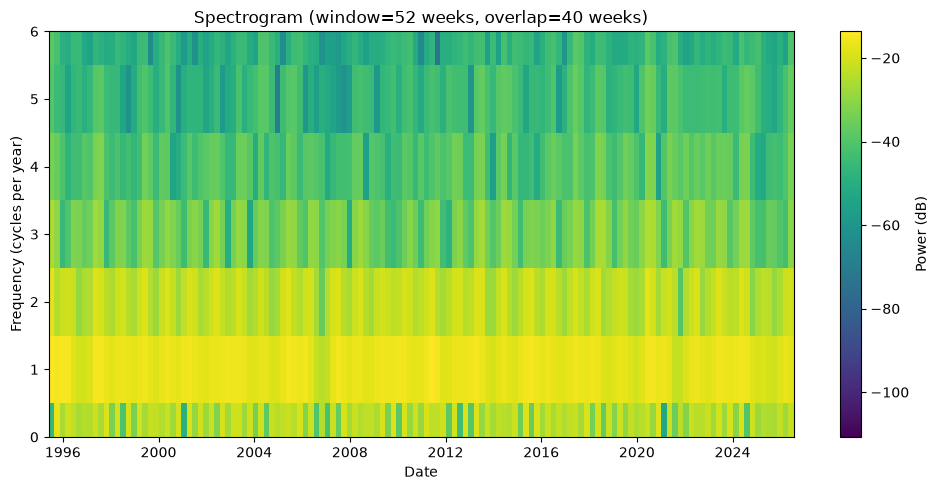

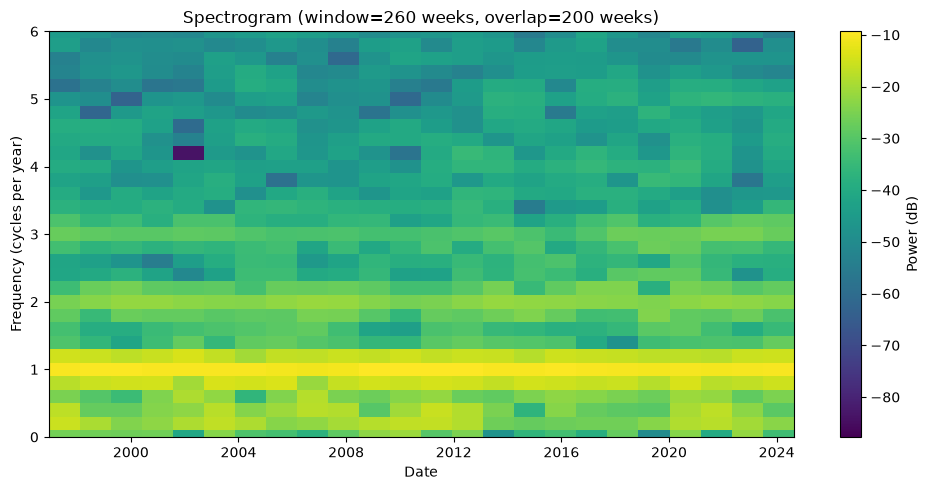

In [12]:
# Compare a short and a long window to see the time/frequency trade-off
for win, ov in [(52, 40), (260, 200)]:
    fig = make_spectrogram(fill, window_length=win, overlap=ov)
    plt.show()